# 5c — Flood-Scenario Road Impacts, Costa Rica

## Purpose

Turn 5b's **basin-scenario** results into a **per-road** impact layer, and map them.

Notebook 5b asks how much worse access to health care gets when a flood closes every exposed road in
one basin. Its unit is the basin. This notebook pushes that answer back down onto the **378
flood-exposed physical roads**, so each road carries the delay of the scenario that removed it. That
per-road layer is what notebook 5d scores as its **Accessibility (A)** sub-index — nothing else in
the CR pipeline produces it.

> ### ⚠ This is not risk
>
> Inherited unchanged from 5b. A scenario removes every flood-exposed road in a basin **with
> certainty** — no fragility curve, no closure probability, no duration. Exposure is being used as a
> screen, not as an impact estimate.

> ### ⚠ `travel_time_impact` is not an ordinary travel time
>
> It is the **unweighted mean positive delay over affected origins, including origins that were cut
> off entirely** and charged 5b's isolation penalty of **7 h**. 31.8 % of affected origin-rows are in
> that state, so the median per-road value (138.6 min under `loc`/hospitals) measures the penalty
> constant about as much as it measures travel time. This is Serbia's definition, kept deliberately
> for comparability — see `MD/5c_Plot_Flood_Scenarios_Accessibility_CR_plan.md` D2 and §3.1. Never
> quote it as "this road adds N minutes" without saying what N contains.

> ### ⚠ The per-road number is a basin number, replicated
>
> Every road removed by the same scenario carries the **same** value. It does not mean that road
> caused that delay — the whole basin group failed together, and each basin is evaluated alone.
> Per-road attribution is notebook 2's single-point-of-failure question, not this one.

## Inputs

| File | Description |
|------|-------------|
| `intermediate_results/parquet/flood_scenarios/scenario_summary.parquet` | 780 rows — scenario × config × sector summary from 5b |
| `intermediate_results/parquet/flood_scenarios/origins_affected.parquet` | 66,035 rows — per-origin detail, affected origins only |
| `intermediate_results/parquet/flood_scenarios/scenario_edges.parquet` | 378 rows — the `scenario_id → physical_edge_id` partition |
| `intermediate_results/gpkg/travel_disruptions/flood_scenario_accessibility.gpkg` | basin geometry (layer `scenarios`) |
| `intermediate_results/gpkg/network/main_network_directed.gpkg` | directed network from 1b (EPSG:8908), for road geometry |
| `input_files/flood_hazard_jrc/jrc_flood_cr_RP100_depth.tif` | JRC RP100 depth raster — opened **only** for the basin depth statistic (§3) |

## Outputs

| File | Description |
|------|-------------|
| `intermediate_results/gpkg/travel_disruptions/flood_scenario_impacts.gpkg` | layer `road_impacts` — 1,512 rows (378 roads × 2 origin sets × 2 sectors), EPSG:8908 |
| `intermediate_results/parquet/flood_scenarios/road_impacts.parquet` | the same table; 5d's input and the re-run cache |
| `intermediate_results/parquet/flood_scenarios/basin_cell_depths.parquet` | per-basin cell-depth statistics |
| `figures/flood_scenario_basin_depth.png` | mean water depth per basin scenario |
| `figures/flood_scenario_hospitals_impact.png`, `…_ebais_impact.png` | increased travel time per sector |
| `figures/flood_scenario_impact_2x2.png` | sector × origin set |

## Processing steps

1. Load 5b's three tables; assert the dimensions reconcile; print the provenance stamp
2. Load the network and dissolve to physical roads on `physical_edge_id`
3. **Per-road impact** — mean positive `delta_h` per (scenario, origin set, sector), merged onto the partition
4. Coverage and buffer diagnostics — which roads get a value, and under which configuration
5. Impact classes — Serbia's bins for the tables, CR bins for the maps
6. **Basin depth** — sample the RP100 raster along each exposed road, flatten per basin, min/mean/max
7. Figures → 8. Save → 9. Reconciliation

## Departures from the Serbia notebook

Recorded in full in `MD/5c_Plot_Flood_Scenarios_Accessibility_CR_plan.md` §5. The four that change numbers:

- **Two sectors, not five** — hospitals and EBAIS. CR has no police, fire, factory or agriculture source.
- **`origin_set` is a column and the buffer is dropped** (D4). Serbia restricts population to a 50 km
  buffer *before* computing its delta, so its metric is implicitly `buf50`; this notebook uses all
  affected origins. Measured cost of the difference: ≤ 6.8 min per scenario.
- **Roads with no affected origin are kept at 0.0**, not dropped (D5), so 5d can tell "measured, no
  impact" from "never evaluated".
- **Basin depth is re-sampled from the raster** (D7), because 4a kept only one scalar per edge and a
  mean of per-road maxima is biased high — it puts 23 basins in the top depth class against the cell
  method's 7.

In [1]:
import sys
import warnings
from pathlib import Path

import contextily as cx
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from matplotlib.patches import Patch
from rasterio.features import rasterize
from rasterio.windows import Window
from rasterio.windows import transform as window_transform
from tqdm.auto import tqdm

BASE_DIR = Path.cwd().parent          # notebook lives in /notebooks
sys.path.append(str(BASE_DIR))

# Shared CR map style: extent, basemap, outline, cities, legend
from src.map_style_cr import add_cr_legend, style_cr_map

warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.simplefilter(action="ignore", category=RuntimeWarning)

# ---- Constants ---------------------------------------------------------
WORKING_EPSG = 8908       # CR-SIRGAS / CRTM05, metres
WEB_MERCATOR = 3857       # basemap tiles only
SCENARIO_RP = 100         # must match 5b; asserted against 5b's provenance stamp below
MIN_IMPACT_H = 0.167      # Serbia's >= 10 min map cut. INHERITED from Serbia, not derived.

# The basemap is added by style_cr_map (src/map_style_cr.py). It uses CartoDB Positron
# with the project's API key: without a key that endpoint returns "API KEY REQUIRED"
# placeholder tiles (verified by fetching tiles for the CR bounding box on 2026-09-15).
# With no key configured it falls back to the keyless Esri.WorldGrayCanvas.

ORIGIN_SETS = ["loc", "wp"]
SECTORS = ["hospitals", "ebais"]
DEFAULT_ORIGIN_SET = "loc"   # matches 5b's DEFAULT_CONFIG; the reporting default

# --- Serbia's impact classes, COPIED VERBATIM from utils/criticality_functions.py -----
# NOT imported. That module does `import xarray` and `from damagescanner.core import
# DamageScanner` at module level, and neither package is installed in criticality2 - so
# importing anything from it raises ModuleNotFoundError in the CR environment. Copying
# the four literals keeps the CR numbers exactly comparable to Serbia's without adding
# two heavy dependencies to the env or editing utils/, which still serves the Serbia
# notebooks. Same precedent as 5b_CR, which imports nothing from utils/.
# If these ever change upstream, they must be changed here too.
IMPACT_BINS = [0.167, 0.333, 0.5, 0.667, 1.0, np.inf]
IMPACT_LABELS = ["10-20 min", "20-30 min", "30-40 min", "40-60 min", "60+ min"]
IMPACT_COLORS = ["#fcbba1", "#fc9272", "#ef3b2c", "#cb181d", "#a50f15"]
IMPACT_WIDTHS = {
    "10-20 min": 1.0, "20-30 min": 1.5, "30-40 min": 2.0,
    "40-60 min": 2.5, "60+ min": 3.0,
}

# Two class columns, deliberately (plan D3). Serbia's bins above are kept for
# comparability but put ~73% of CR roads in the single '60+ min' class, because the 7 h
# isolation penalty sits inside the metric - so the maps use breaks chosen against the
# measured CR quantiles (p20 = 32.5 min, p50 = 138.6, p80 = 339).
CR_IMPACT_BINS = [0.0, 0.5, 1.0, 2.0, 4.0, np.inf]
CR_IMPACT_LABELS = ["< 30 min", "30-60 min", "1-2 h", "2-4 h", "4 h+"]
CR_IMPACT_WIDTHS = {"< 30 min": 1.0, "30-60 min": 1.5, "1-2 h": 2.0, "2-4 h": 2.5, "4 h+": 3.0}

# Serbia's basin depth classes, kept unchanged (plan D7).
DEPTH_BINS = [0, 1, 2, 3, 4, np.inf]
DEPTH_LABELS = ["0-1m", "1-2m", "2-3m", "3-4m", "4m+"]
DEPTH_COLORS = ["#f7fbff", "#c6dbef", "#6baed6", "#2171b5", "#08306b"]


def print_delay_category_counts(exposed_edges, label):
    """How many roads fall in each Serbia delay category.

    Copied from utils/criticality_functions.py for the reason given above; behaviour is
    unchanged, so its output stays comparable with the Serbia notebook's.
    """
    print(f"\nDelay categories - {label}:")
    if exposed_edges is None or len(exposed_edges) == 0:
        print("  (no exposed roads with >= 10 min delay)")
        return
    counts = exposed_edges["impact_class"].value_counts().reindex(IMPACT_LABELS, fill_value=0)
    total = int(counts.sum())
    for lbl in IMPACT_LABELS:
        c = int(counts[lbl])
        print(f"  {lbl:10s}: {c:6d} ({c / total * 100 if total else 0.0:5.1f}%)")
    print(f"  {'Total':10s}: {total:6d}")
    delays_min = pd.to_numeric(exposed_edges["travel_time_impact"], errors="coerce") * 60
    mid_labels = ["20-30 min", "30-40 min", "40-60 min"]
    mid_count = int(counts[mid_labels].sum())
    print(f"  Mean delay   : {delays_min.mean():6.1f} min")
    print(f"  Median delay : {delays_min.median():6.1f} min")
    print(f"  Share 20-60 min: {mid_count / total * 100 if total else 0.0:5.1f}% ({mid_count}/{total})")


# ---- Paths -------------------------------------------------------------
data_path = BASE_DIR / "input_files"
figure_path = BASE_DIR / "figures"
intermediate_path = BASE_DIR / "intermediate_results"
parquet_dir = intermediate_path / "parquet" / "flood_scenarios"
gpkg_dir = intermediate_path / "gpkg" / "travel_disruptions"

# Inputs (all from 5b, except the raster - see plan D7 / I9)
summary_parquet = parquet_dir / "scenario_summary.parquet"
origins_parquet = parquet_dir / "origins_affected.parquet"
edges_parquet = parquet_dir / "scenario_edges.parquet"
scenario_gpkg = gpkg_dir / "flood_scenario_accessibility.gpkg"
network_gpkg = intermediate_path / "gpkg" / "network" / "main_network_directed.gpkg"
flood_raster = data_path / "flood_hazard_jrc" / f"jrc_flood_cr_RP{SCENARIO_RP}_depth.tif"

# Outputs
impacts_gpkg = gpkg_dir / "flood_scenario_impacts.gpkg"
road_impacts_parquet = parquet_dir / "road_impacts.parquet"
basin_depths_parquet = parquet_dir / "basin_cell_depths.parquet"

for p in (figure_path, gpkg_dir, parquet_dir):
    p.mkdir(parents=True, exist_ok=True)

required = [summary_parquet, origins_parquet, edges_parquet,
            scenario_gpkg, network_gpkg, flood_raster]
missing = [p for p in required if not p.exists()]
if missing:
    raise FileNotFoundError(
        "Missing inputs:\n  " + "\n  ".join(str(p) for p in missing)
        + "\n\nRun 5b_Run_Flood_Scenarios_Accessibility_CR.ipynb first. If a path lives on "
          "OneDrive, make sure the folder is downloaded locally ('Always keep on this device') - "
          "cloud placeholders cannot be opened."
    )
print("All inputs present.")

All inputs present.


## 1 · Inputs from 5b

Provenance — return period, depth threshold, isolation penalty, scenario unit — is **read from 5b's
output**, not restated here, so the two notebooks cannot drift apart.

In [2]:
summary = pd.read_parquet(summary_parquet)
origins_affected = pd.read_parquet(origins_parquet)
scenario_edges = pd.read_parquet(edges_parquet)

n_scenarios = summary["scenario_id"].nunique()
configs = sorted(summary["config"].unique())
sectors_present = sorted(summary["sector"].unique())

assert len(summary) == n_scenarios * len(configs) * len(sectors_present), (
    "5b summary does not reconcile: scenarios x configs x sectors != rows"
)
assert set(SECTORS).issubset(sectors_present), f"Expected {SECTORS} within {sectors_present}"
# The partition must stay 1:1 - 5b assigns each exposed road to exactly one basin by
# majority length. If that ever changes, the merge in section 2 would fan out silently.
assert scenario_edges["physical_edge_id"].is_unique, (
    "A physical road is assigned to more than one scenario - the partition is no longer 1:1"
)

prov = summary[["scenario_rp", "flood_threshold_m", "isolation_penalty_h",
                "buffer_m", "scenario_unit"]].drop_duplicates()
assert len(prov) == 1, "5b rows carry more than one provenance stamp"
prov = prov.iloc[0]
assert int(prov["scenario_rp"]) == SCENARIO_RP, (
    f"5b ran at RP{int(prov['scenario_rp'])}, this notebook is configured for RP{SCENARIO_RP}"
)

ISOLATION_PENALTY_H = float(prov["isolation_penalty_h"])

print(f"Scenarios         : {n_scenarios}")
print(f"Configs in 5b     : {configs}")
print(f"Sectors in 5b     : {sectors_present}")
print(f"Summary rows      : {len(summary):,}")
print(f"Affected origins  : {len(origins_affected):,} rows")
print(f"Partition         : {len(scenario_edges):,} physical roads, 1:1 to scenarios")
print()
print("Provenance, read from 5b rather than restated:")
print(f"  scenario unit     : {prov['scenario_unit']}")
print(f"  return period     : RP{int(prov['scenario_rp'])}")
print(f"  depth threshold   : > {prov['flood_threshold_m']} m   (inherited from Serbia, not derived)")
print(f"  isolation penalty : {ISOLATION_PENALTY_H:.0f} h   <- this sits INSIDE travel_time_impact")
print(f"  5b buffer         : {int(prov['buffer_m']) / 1000:.0f} km   "
      "(reported in section 2, then dropped - plan D4)")
print()
print(f"This notebook reports two of those sectors ({SECTORS}); 'ebais_noncolocated' is not")
print("carried into the road layer because it shares its numerator with 'ebais' and differs")
print("only in a denominator this metric does not have (5b I14, plan D6).")

Scenarios         : 65
Configs in 5b     : ['loc_buf50', 'loc_nobuf', 'wp_buf50', 'wp_nobuf']
Sectors in 5b     : ['ebais', 'ebais_noncolocated', 'hospitals']
Summary rows      : 780
Affected origins  : 66,035 rows
Partition         : 378 physical roads, 1:1 to scenarios

Provenance, read from 5b rather than restated:
  scenario unit     : hybas_na_lev08
  return period     : RP100
  depth threshold   : > 0.25 m   (inherited from Serbia, not derived)
  isolation penalty : 7 h   <- this sits INSIDE travel_time_impact
  5b buffer         : 50 km   (reported in section 2, then dropped - plan D4)

This notebook reports two of those sectors (['hospitals', 'ebais']); 'ebais_noncolocated' is not
carried into the road layer because it shares its numerator with 'ebais' and differs
only in a denominator this metric does not have (5b I14, plan D6).


In [3]:
network = gpd.read_file(network_gpkg, layer="main_network_directed")
assert network.crs.to_epsg() == WORKING_EPSG, f"Network CRS is {network.crs}, expected {WORKING_EPSG}"

# One geometry per physical road - the unit 5b removed, and the unit this layer reports.
# Serbia works in single directed edges keyed on osm_id; CR has neither (plan A2, A6).
roads = (
    network.dissolve("physical_edge_id", aggfunc={"road_length": "sum"})
    .reset_index()[["physical_edge_id", "road_length", "geometry"]]
)

# Readable identifiers, taken from the longest directed edge of each physical road.
label_cols = [c for c in ("ID_TRAMO", "NOMBRE", "CLASE") if c in network.columns]
if label_cols:
    longest = (
        network.sort_values("road_length", ascending=False)
        .drop_duplicates("physical_edge_id")
    )
    roads = roads.merge(
        longest[["physical_edge_id"] + label_cols],
        on="physical_edge_id", how="left", validate="1:1",
    )

exposed_roads = roads.merge(
    scenario_edges, on="physical_edge_id", how="inner", validate="1:1"
)

print(f"Network             : {len(network):,} directed edges, "
      f"{roads['physical_edge_id'].nunique():,} physical roads")
print(f"Flood-exposed roads : {len(exposed_roads):,}  "
      f"({exposed_roads['road_length'].sum():,.0f} km, "
      f"{100 * exposed_roads['road_length'].sum() / roads['road_length'].sum():.1f}% of network)")
print(f"Identifier columns  : {label_cols or 'none found'}")
print(f"Basins represented  : {exposed_roads['scenario_id'].nunique()}")

Network             : 9,764 directed edges, 5,012 physical roads
Flood-exposed roads : 378  (4,839 km, 16.4% of network)
Identifier columns  : ['ID_TRAMO', 'NOMBRE', 'CLASE']
Basins represented  : 65


## 2 · Per-road impact

Serbia's definition, kept deliberately (plan D2): the **unweighted mean of positive travel-time
deltas** over the scenario's affected origins, with isolation-penalised origins included in the mean.

The result is `travel_time_impact`, in **hours**, one value per road × origin set × sector.

In [4]:
# Serbia's metric (plan D2), reproduced on CR's tables.
#
# 5b's origins_affected already holds exactly the delta > 0 rows, and has already
# replaced unreachability with the isolation penalty - so penalised origins are inside
# this mean, exactly as they are inside Serbia's (src/5b:50 charges a flat 12 h and
# keeps those rows in Delta; CR charges a derived 7 h instead).
#
# What that means for anyone reading the column: it is NOT "how much longer the trip
# takes". It blends real delay with a modelling constant applied to origins that were
# cut off entirely. See the header cell.
per_scenario = (
    origins_affected.groupby(["scenario_id", "origin_set", "sector"])
    .agg(
        travel_time_impact=("delta_h", "mean"),
        n_affected_origins=("origin_id", "size"),
        pop_affected=("population", "sum"),
    )
    .reset_index()
)

# The full grid: every exposed road under every origin set and sector. Roads whose
# scenario affected nobody stay in, at 0.0 (plan D5). Serbia drops them; 5d's
# add_impact_column turns unjoined roads into NaN, which would make "measured, no
# impact" and "never evaluated" indistinguishable downstream.
combos = pd.DataFrame(
    [(o, s) for o in ORIGIN_SETS for s in SECTORS], columns=["origin_set", "sector"]
)
road_impacts = (
    exposed_roads.merge(combos, how="cross")
    .merge(per_scenario, on=["scenario_id", "origin_set", "sector"],
           how="left", validate="m:1")
)

road_impacts["n_affected_origins"] = road_impacts["n_affected_origins"].fillna(0).astype(int)
road_impacts["pop_affected"] = road_impacts["pop_affected"].fillna(0.0)
road_impacts["travel_time_impact"] = road_impacts["travel_time_impact"].fillna(0.0)
road_impacts["impact_min"] = road_impacts["travel_time_impact"] * 60
road_impacts = gpd.GeoDataFrame(road_impacts, geometry="geometry", crs=f"EPSG:{WORKING_EPSG}")

expected = len(exposed_roads) * len(ORIGIN_SETS) * len(SECTORS)
assert len(road_impacts) == expected, f"{len(road_impacts)} rows, expected {expected}"

print(f"Per-road impact table: {len(road_impacts):,} rows "
      f"({len(exposed_roads)} roads x {len(ORIGIN_SETS)} origin sets x {len(SECTORS)} sectors)\n")
print("travel_time_impact in MINUTES, over roads with a non-zero value:\n")
print(
    road_impacts[road_impacts["travel_time_impact"] > 0]
    .groupby(["origin_set", "sector"])["impact_min"]
    .describe()[["count", "mean", "50%", "max"]]
    .round(1)
    .to_string()
)
print(f"\nFor scale: the isolation penalty is {ISOLATION_PENALTY_H * 60:.0f} min.")

Per-road impact table: 1,512 rows (378 roads x 2 origin sets x 2 sectors)

travel_time_impact in MINUTES, over roads with a non-zero value:

                      count   mean    50%    max
origin_set sector                               
loc        ebais      138.0  268.7  400.8  418.0
           hospitals  326.0  168.4  138.6  389.7
wp         ebais      359.0  256.7  277.7  416.7
           hospitals  377.0  153.0  104.9  368.8

For scale: the isolation penalty is 420 min.


In [5]:
# --- Coverage: how much of the exposed network gets a value at all? ---
# A road receives an impact only if SOME origin was affected by its scenario, so the
# configuration decides coverage. This is the largest sensitivity in the notebook and
# the reason origin_set is a column rather than a silent default (plan D4, section 3.2).
cov = (
    road_impacts.assign(has_value=road_impacts["n_affected_origins"] > 0)
    .groupby(["origin_set", "sector"])
    .agg(
        roads=("physical_edge_id", "nunique"),
        roads_with_value=("has_value", "sum"),
        roads_ge_10min=("travel_time_impact", lambda s: int((s >= MIN_IMPACT_H).sum())),
        median_min=("impact_min", lambda s: round(float(s[s > 0].median()), 1)
                    if (s > 0).any() else np.nan),
    )
)
cov["pct_covered"] = (100 * cov["roads_with_value"] / cov["roads"]).round(1)
print(f"Coverage of the {len(exposed_roads)} flood-exposed roads, per configuration:\n")
print(cov.to_string())
print("\n  Roads with no value belong to scenarios that affected nobody. They are KEPT at 0.0")
print("  (plan D5) so 5d can distinguish 'measured, no impact' from 'never evaluated'.")

# --- Buffer: does 5b's 50 km mask change this metric? ---
# 5b computed everything unbuffered and applied the buffer as a mask over origins.
# Serbia instead restricts population to the buffer BEFORE computing its delta, so
# Serbia's metric is implicitly buf50. This measures the size of that difference.
rows = []
for (okey, sec), grp in origins_affected.groupby(["origin_set", "sector"]):
    if sec not in SECTORS:
        continue
    a = grp.groupby("scenario_id")["delta_h"].mean()
    b = grp[grp["in_buffer"]].groupby("scenario_id")["delta_h"].mean()
    d = (a - b.reindex(a.index)).abs().dropna()
    rows.append({
        "origin_set": okey,
        "sector": sec,
        "scenarios": len(d),
        "max_abs_diff_min": round(float(d.max() * 60), 2) if len(d) else np.nan,
        "identical": bool((d < 1e-12).all()) if len(d) else True,
    })
print("\n\nBuffer check - unbuffered vs 50 km buffered, on this metric:\n")
print(pd.DataFrame(rows).to_string(index=False))
print("\n  The buffer axis is reported here and then DROPPED (plan D4): it moves the metric by")
print("  at most a few minutes and changes no road's coverage. This notebook is UNBUFFERED,")
print("  which is a DEPARTURE from Serbia's implicit buf50, not an absence of a choice.")

Coverage of the 378 flood-exposed roads, per configuration:

                      roads  roads_with_value  roads_ge_10min  median_min  pct_covered
origin_set sector                                                                     
loc        ebais        378               138             113       400.8         36.5
           hospitals    378               326             307       138.6         86.2
wp         ebais        378               359             335       277.7         95.0
           hospitals    378               377             366       104.9         99.7

  Roads with no value belong to scenarios that affected nobody. They are KEPT at 0.0
  (plan D5) so 5d can distinguish 'measured, no impact' from 'never evaluated'.


Buffer check - unbuffered vs 50 km buffered, on this metric:

origin_set    sector  scenarios  max_abs_diff_min  identical
       loc     ebais         17              0.00       True
       loc hospitals         46              6.77      False
    

In [6]:
# Two class columns from the same number; nothing is recomputed (plan D3).
#
# impact_class    - Serbia's breaks, for the tables and for cross-country comparability.
#                   IMPACT_BINS starts at 0.167 h, so zero-impact roads fall out as NaN.
# impact_class_cr - CR breaks, for the maps, because Serbia's top class absorbs most of
#                   the CR roads once the isolation penalty is inside the metric.
road_impacts["impact_class"] = pd.cut(
    road_impacts["travel_time_impact"],
    bins=IMPACT_BINS, labels=IMPACT_LABELS, include_lowest=True,
)
road_impacts["impact_class_cr"] = pd.cut(
    road_impacts["travel_time_impact"],
    bins=CR_IMPACT_BINS, labels=CR_IMPACT_LABELS, include_lowest=True,
)
# A zero-impact road is not "< 30 min" - it is unclassified. Only the CR bins need this,
# since they start at 0.
road_impacts.loc[road_impacts["travel_time_impact"] <= 0, "impact_class_cr"] = np.nan

mapped = road_impacts[road_impacts["travel_time_impact"] >= MIN_IMPACT_H]
sub = mapped[mapped["origin_set"] == DEFAULT_ORIGIN_SET]

print(f"Roads clearing Serbia's >= 10 min cut: {len(mapped):,} of {len(road_impacts):,} rows")
print(f"Shown below for the reporting default origin set ('{DEFAULT_ORIGIN_SET}'), both sectors.\n")
print("Serbia bins (kept for comparability):")
print(sub["impact_class"].value_counts().reindex(IMPACT_LABELS).to_string())
print("\nCR bins (used for the maps):")
print(sub["impact_class_cr"].value_counts().reindex(CR_IMPACT_LABELS).to_string())
print("\n  Serbia's open-ended top class absorbs most CR roads, which is why the maps use")
print("  the CR breaks. Both columns are saved; any table quoting a class must say which.")

# Serbia's own reporting helper, imported unchanged and fed the Serbia bins.
for sector in SECTORS:
    print_delay_category_counts(
        mapped[(mapped["origin_set"] == DEFAULT_ORIGIN_SET) & (mapped["sector"] == sector)],
        f"{sector} [{DEFAULT_ORIGIN_SET}]",
    )

Roads clearing Serbia's >= 10 min cut: 1,121 of 1,512 rows
Shown below for the reporting default origin set ('loc'), both sectors.

Serbia bins (kept for comparability):
impact_class
10-20 min     44
20-30 min     14
30-40 min     24
40-60 min     18
60+ min      320

CR bins (used for the maps):
impact_class_cr
< 30 min      58
30-60 min     42
1-2 h         26
2-4 h         87
4 h+         207

  Serbia's open-ended top class absorbs most CR roads, which is why the maps use
  the CR breaks. Both columns are saved; any table quoting a class must say which.

Delay categories - hospitals [loc]:
  10-20 min :     28 (  9.1%)
  20-30 min :     14 (  4.6%)
  30-40 min :     24 (  7.8%)
  40-60 min :     18 (  5.9%)
  60+ min   :    223 ( 72.6%)
  Total     :    307
  Mean delay   :  178.4 min
  Median delay :  138.6 min
  Share 20-60 min:  18.2% (56/307)

Delay categories - ebais [loc]:
  10-20 min :     16 ( 14.2%)
  20-30 min :      0 (  0.0%)
  30-40 min :      0 (  0.0%)
  40-60 min : 

## 3 · Basin water depth

Serbia flattens every per-cell depth value across a basin's flooded edges into one list and takes
min/mean/max (`src/5b:416-445`). 4a discarded CR's per-cell distributions — it keeps one scalar per
edge — so the scalar-only equivalent would be a **mean of per-road maxima**, which is biased high.

This section reproduces Serbia's method instead (plan D7), re-sampling the RP100 raster with
`rasterio`, since `exactextract` is not installed in `criticality2`.

**Containment (plan I9).** These values feed the descriptive depth figure **only**. Which roads are
exposed, the 0.25 m threshold and the basin partition all still come from 4a via 5b's
`scenario_edges.parquet` — so the two samplers cannot disagree about *which* roads flood, only about
how deep.

In [7]:
def sample_depths_along_roads(roads_gdf, raster_path):
    """Per-road array of flood-depth cell values, as exactextract reports for a LineString.

    Rasterising each line with all_touched=True selects exactly the cells the geometry
    passes through, which is what Serbia's exact_extract(..., ["coverage", "values"])
    call returns before it flattens them.
    """
    with rasterio.open(raster_path) as src:
        arr = src.read(1)
        geoms = roads_gdf.to_crs(src.crs).geometry
        out = {}
        for pid, geom in tqdm(
            zip(roads_gdf["physical_edge_id"], geoms),
            total=len(roads_gdf), desc="sampling roads",
        ):
            minx, miny, maxx, maxy = geom.bounds
            r0, c0 = src.index(minx, maxy)
            r1, c1 = src.index(maxx, miny)
            r0, r1 = max(0, min(r0, r1) - 1), min(src.height, max(r0, r1) + 2)
            c0, c1 = max(0, min(c0, c1) - 1), min(src.width, max(c0, c1) + 2)
            win = Window(c0, r0, c1 - c0, r1 - r0)
            mask = rasterize(
                [(geom, 1)],
                out_shape=(r1 - r0, c1 - c0),
                transform=window_transform(win, src.transform),
                all_touched=True,
                dtype="uint8",
            ).astype(bool)
            vals = arr[r0:r1, c0:c1][mask]
            out[pid] = vals[(vals != src.nodata) & np.isfinite(vals)]
    return out


if basin_depths_parquet.exists():
    basin_depths = pd.read_parquet(basin_depths_parquet)
    print(f"Loaded cached basin depths ({basin_depths_parquet.name}). Delete the file to re-sample.")
else:
    per_road_cells = sample_depths_along_roads(exposed_roads, flood_raster)
    rows = []
    for sid, grp in exposed_roads.groupby("scenario_id"):
        # Flatten the per-road arrays KEEPING duplicates, exactly as Serbia does: a cell
        # touched by two roads counts twice in the basin mean. Inherited, not chosen.
        merged = np.concatenate([per_road_cells[p] for p in grp["physical_edge_id"]])
        rows.append({
            "scenario_id": sid,
            "n_roads": len(grp),
            "n_cells": int(len(merged)),
            "cell_min_m": float(merged.min()) if len(merged) else np.nan,
            "cell_mean_m": float(merged.mean()) if len(merged) else np.nan,
            "cell_max_m": float(merged.max()) if len(merged) else np.nan,
        })
    basin_depths = pd.DataFrame(rows)
    basin_depths.to_parquet(basin_depths_parquet, index=False)
    print(f"Sampled {basin_depths['n_cells'].sum():,} cells over {len(exposed_roads)} roads "
          f"-> {basin_depths_parquet.name}")

print()
print(basin_depths[["n_cells", "cell_min_m", "cell_mean_m", "cell_max_m"]]
      .describe().round(2).to_string())

# What the scalar-only route would have said instead - the measured size of 5b's I3.
scal = (
    summary[summary["sector"] == "hospitals"]
    .drop_duplicates("scenario_id")
    .set_index("scenario_id")["depth_mean_of_max_m"]
)
cmp_depth = basin_depths.set_index("scenario_id").join(scal)
diff = cmp_depth["cell_mean_m"] - cmp_depth["depth_mean_of_max_m"]
print(f"\nCell mean vs 4a's mean-of-maxima: median difference {diff.median():+.2f} m; "
      f"the cell mean is lower in {(diff < 0).sum()} of {len(diff)} basins.")
print("  The scalar route is biased high by construction - this is why D7 re-samples.")
print(f"\nMaximum sampled depth: {basin_depths['cell_max_m'].max():.1f} m. Depths this large are")
print("  implausible and are flagged by 4a as flood_depth_implausible - they are in the JRC")
print("  raster itself, so re-sampling does not fix them (plan I6).")

Loaded cached basin depths (basin_cell_depths.parquet). Delete the file to re-sample.

       n_cells  cell_min_m  cell_mean_m  cell_max_m
count    65.00       65.00        65.00       65.00
mean    103.82        0.47         2.31        6.69
std     121.27        0.77         1.71        6.50
min       1.00        0.10         0.58        1.00
25%      11.00        0.11         1.00        2.32
50%      58.00        0.16         1.76        5.30
75%     171.00        0.67         3.03        8.55
max     544.00        5.49        10.15       37.29

Cell mean vs 4a's mean-of-maxima: median difference -0.99 m; the cell mean is lower in 55 of 65 basins.
  The scalar route is biased high by construction - this is why D7 re-samples.

Maximum sampled depth: 37.3 m. Depths this large are
  implausible and are flagged by 4a as flood_depth_implausible - they are in the JRC
  raster itself, so re-sampling does not fix them (plan I6).


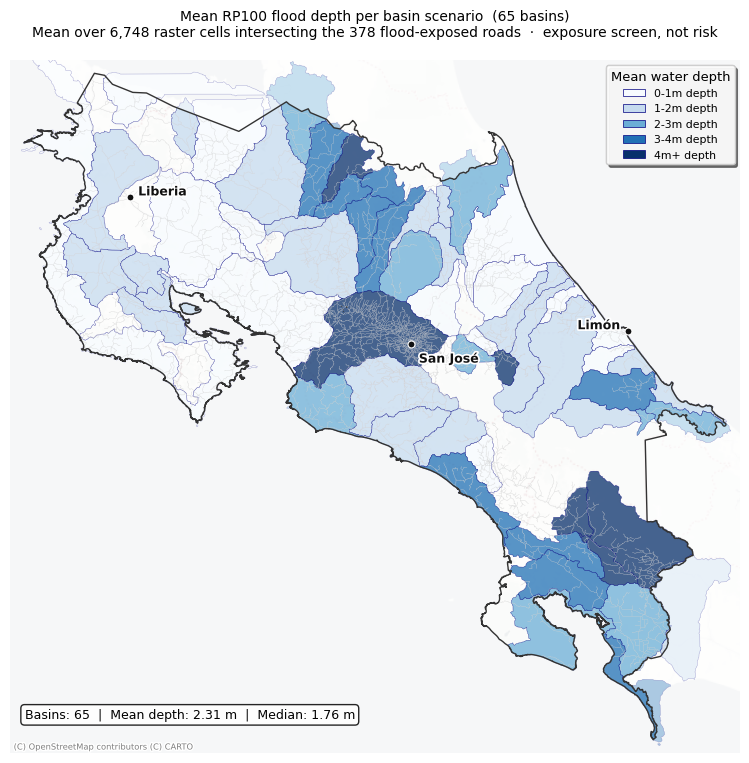

Basins per depth class:
depth_class
0-1m    16
1-2m    23
2-3m     9
3-4m    10
4m+      7


In [ ]:
basins = gpd.read_file(scenario_gpkg, layer="scenarios")
basins = basins.drop_duplicates("scenario_id")[["scenario_id", "geometry"]]
basins = basins.merge(basin_depths, on="scenario_id", how="inner", validate="1:1")
basins["depth_class"] = pd.cut(
    basins["cell_mean_m"], bins=DEPTH_BINS, labels=DEPTH_LABELS, include_lowest=True
)

# Everything below EPSG:3857 is for basemap tiles only - CR works in 8908 (CLAUDE.md).
basins_3857 = basins.to_crs(WEB_MERCATOR)
network_3857 = network.to_crs(WEB_MERCATOR)

fig, ax = plt.subplots(1, 1, figsize=(11, 9), facecolor="white")
network_3857.plot(ax=ax, linewidth=0.2, color="lightgrey", alpha=0.6)
for label, color in zip(DEPTH_LABELS, DEPTH_COLORS):
    sel = basins_3857[basins_3857["depth_class"] == label]
    if len(sel):
        sel.plot(ax=ax, color=color, linewidth=0.3, edgecolor="navy", alpha=0.75)
style_cr_map(
    ax, WEB_MERCATOR,
    legend_handles=[Patch(facecolor=c, label=f"{lbl} depth", edgecolor="navy", linewidth=0.5)
                    for lbl, c in zip(DEPTH_LABELS, DEPTH_COLORS)],
    legend_title="Exposed road segments mean depth per basins",
)
ax.set_title(
    f"Mean RP{SCENARIO_RP} flood depth per basin scenario  ({len(basins)} basins)\n"
    f"Mean over {int(basin_depths['n_cells'].sum()):,} raster cells intersecting the "
    f"{len(exposed_roads)} flood-exposed roads  ·  exposure screen, not risk",
    fontsize=10,
)
ax.text(
    0.02, 0.05,
    f"Basins: {len(basins)}  |  Mean depth: {basins['cell_mean_m'].mean():.2f} m  |  "
    f"Median: {basins['cell_mean_m'].median():.2f} m",
    transform=ax.transAxes, fontsize=9, zorder=30,   # above the outside-fade layer
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.85),
)
fig.savefig(figure_path / "flood_scenario_basin_depth.png", dpi=200, bbox_inches="tight")
plt.show()

print("Basins per depth class:")
print(basins["depth_class"].value_counts().reindex(DEPTH_LABELS).to_string())

## 4 · Impact maps

Each road is coloured by the delay of **its own basin scenario, evaluated alone** — never a national
event. Only roads clearing Serbia's ≥ 10 min cut are drawn; the saved layer keeps all of them.

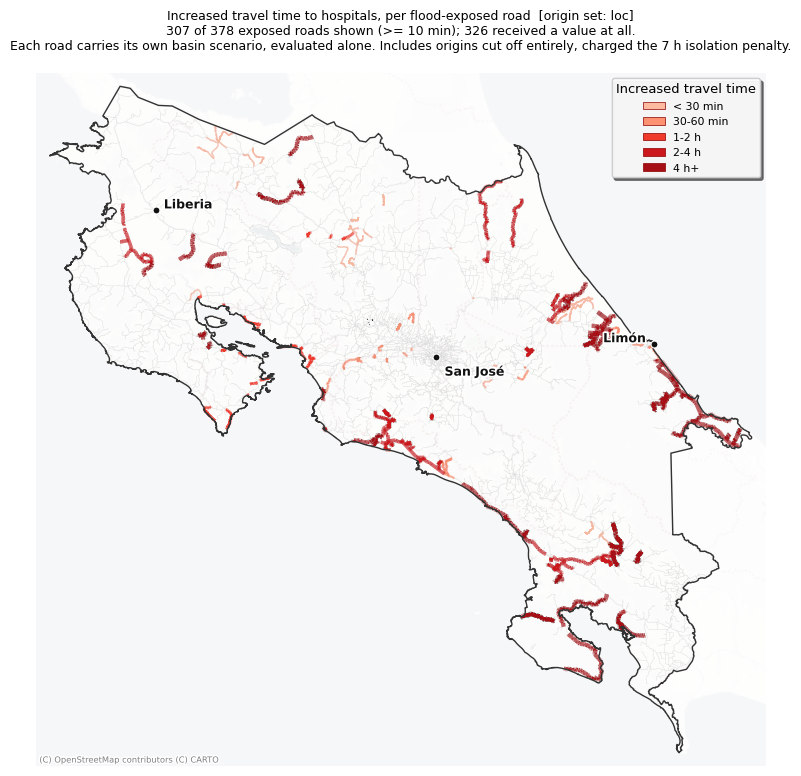

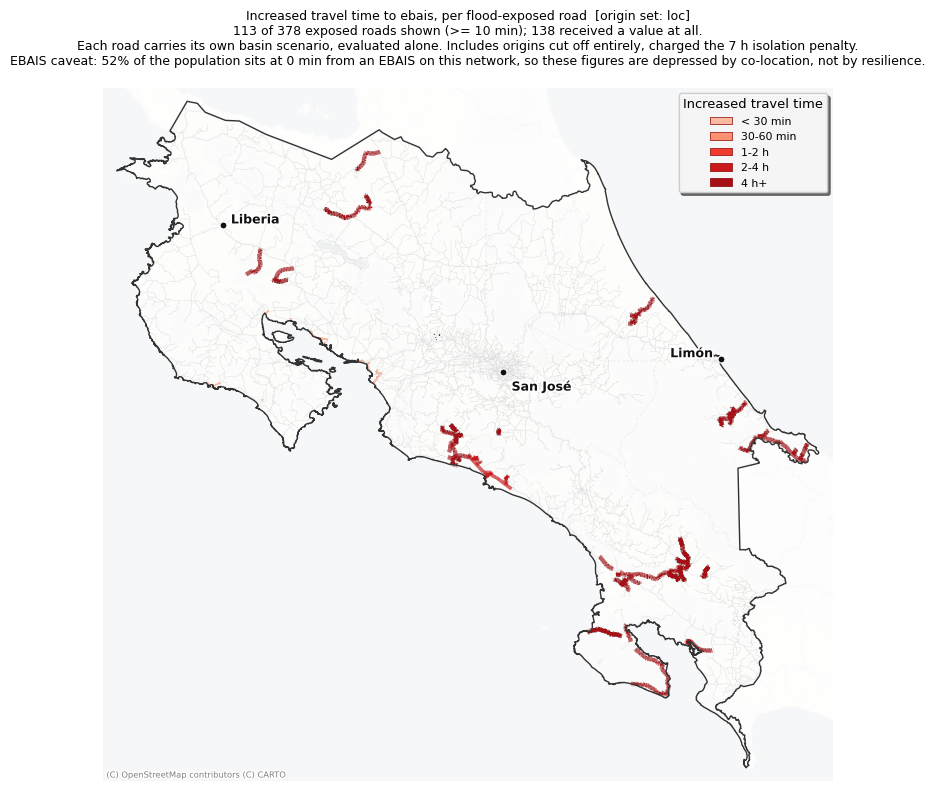

In [9]:
def plot_impact_map(gdf, base_3857, title, out_name, legend_title="Increased travel time",
                    class_col="impact_class_cr", labels=None, colors=IMPACT_COLORS,
                    widths=None, dpi=200):
    """One map of per-road impact over the muted base network.

    Deliberately NOT utils...plot_service_criticality: that helper is hard-wired to
    IMPACT_LABELS, so it can only render Serbia's bins - and those put most CR roads in
    a single class (plan D3). It is also unimportable in criticality2 (see the setup
    cell). The colour ramp is shared so the two read as one family, and utils/ is left
    untouched for the Serbia notebooks.
    """
    labels = labels or CR_IMPACT_LABELS
    widths = widths or CR_IMPACT_WIDTHS
    fig, ax = plt.subplots(1, 1, figsize=(11, 9), facecolor="white")
    base_3857.plot(ax=ax, linewidth=0.2, color="lightgrey", alpha=0.6)
    drawn = gdf.to_crs(WEB_MERCATOR)
    for i, (label, color) in enumerate(zip(labels, colors)):
        sel = drawn[drawn[class_col] == label]
        if len(sel):
            sel.plot(ax=ax, color=color, linewidth=widths[label], alpha=0.9, zorder=5 + i)
    style_cr_map(
        ax, WEB_MERCATOR,
        legend_handles=[Patch(facecolor=c, label=lbl, edgecolor="darkred", linewidth=0.5)
                        for lbl, c in zip(labels, colors)],
        legend_title=legend_title,
    )
    ax.set_title(title, fontsize=9)
    fig.savefig(Path(figure_path) / out_name, dpi=dpi, bbox_inches="tight")
    plt.show()


for sector in SECTORS:
    arm = road_impacts[(road_impacts["origin_set"] == DEFAULT_ORIGIN_SET)
                       & (road_impacts["sector"] == sector)]
    sel = arm[arm["travel_time_impact"] >= MIN_IMPACT_H]
    n_cov = int((arm["n_affected_origins"] > 0).sum())

    caveat = ""
    if sector == "ebais":
        caveat = ("\nEBAIS caveat: 52% of the population sits at 0 min from an EBAIS on this "
                  "network, so these figures are depressed by co-location, not by resilience.")
    plot_impact_map(
        sel, network_3857,
        title=(
            f"Increased travel time to {sector}, per flood-exposed road  "
            f"[origin set: {DEFAULT_ORIGIN_SET}]\n"
            f"{len(sel)} of {len(exposed_roads)} exposed roads shown (>= 10 min); "
            f"{n_cov} received a value at all.\n"
            f"Each road carries its own basin scenario, evaluated alone. Includes origins "
            f"cut off entirely, charged the {ISOLATION_PENALTY_H:.0f} h isolation penalty."
            f"{caveat}"
        ),
        out_name=f"flood_scenario_{sector}_impact.png",
    )

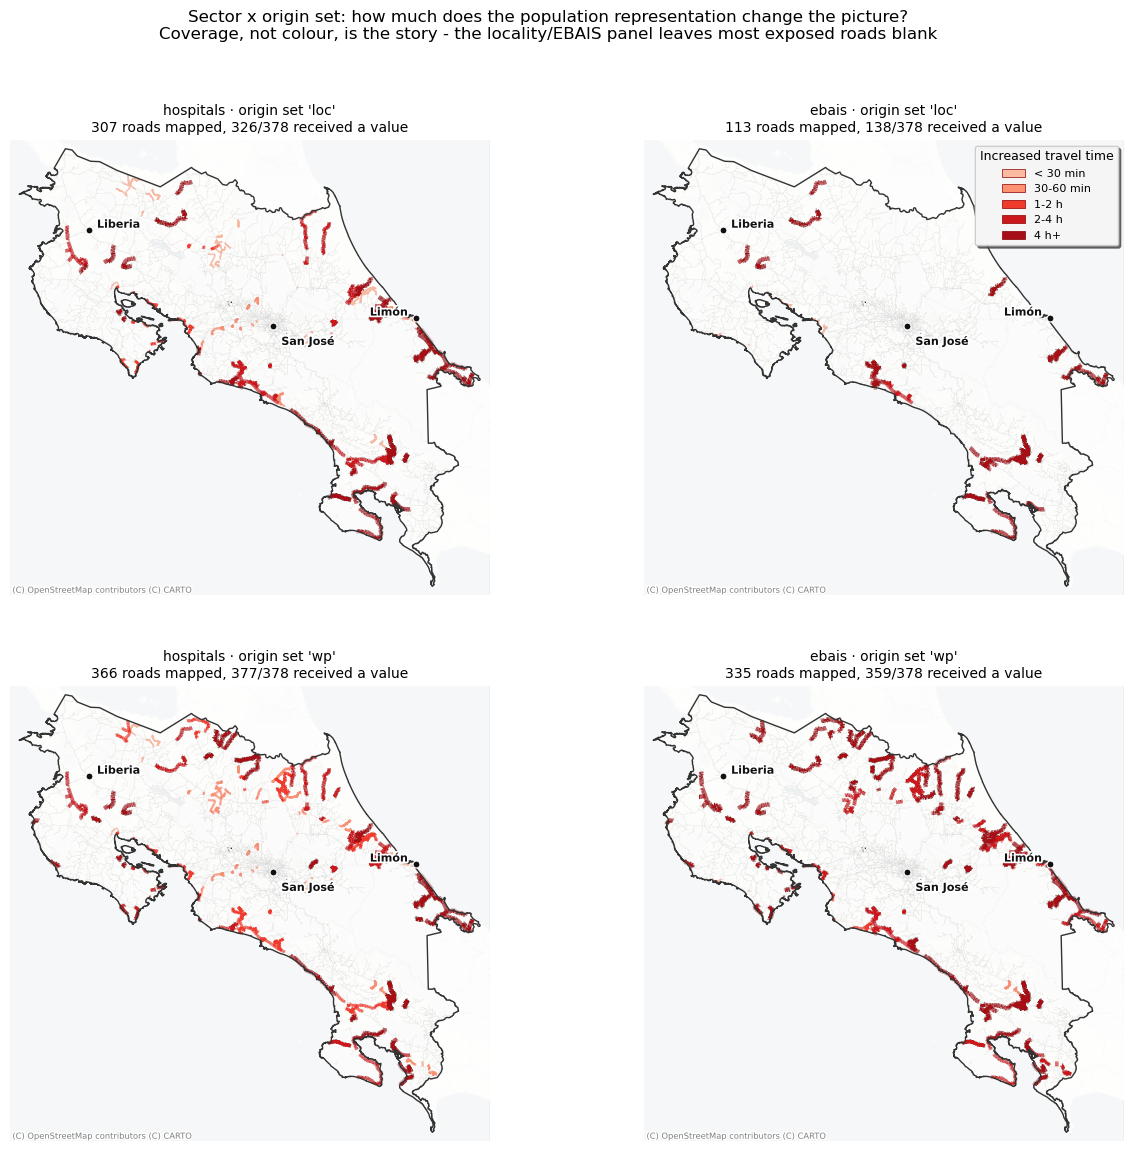

In [10]:
# Serbia's 2x2 is four sectors (hospitals / factories / police / fire). CR has two, so
# the same four panels become the sensitivity display instead: sector x origin set.
# This is the figure that shows how much the population representation is doing - the
# coverage swing in section 2 is visible here as roads present or absent.
panels = [(o, s) for o in ORIGIN_SETS for s in SECTORS]

fig, axes = plt.subplots(2, 2, figsize=(15, 13), facecolor="white")
for ax, (okey, sector) in zip(axes.ravel(), panels):
    arm = road_impacts[(road_impacts["origin_set"] == okey) & (road_impacts["sector"] == sector)]
    sel = arm[arm["travel_time_impact"] >= MIN_IMPACT_H].to_crs(WEB_MERCATOR)
    n_cov = int((arm["n_affected_origins"] > 0).sum())

    network_3857.plot(ax=ax, linewidth=0.15, color="lightgrey", alpha=0.6)
    for i, (label, color) in enumerate(zip(CR_IMPACT_LABELS, IMPACT_COLORS)):
        s2 = sel[sel["impact_class_cr"] == label]
        if len(s2):
            s2.plot(ax=ax, color=color, linewidth=CR_IMPACT_WIDTHS[label], alpha=0.9, zorder=5 + i)
    style_cr_map(ax, WEB_MERCATOR, city_fontsize=8)
    ax.set_title(
        f"{sector} · origin set '{okey}'\n{len(sel)} roads mapped, "
        f"{n_cov}/{len(exposed_roads)} received a value",
        fontsize=10,
    )

# One shared legend, in the figure's upper-right panel.
add_cr_legend(
    axes[0, 1],
    [Patch(facecolor=c, label=lbl, edgecolor="darkred", linewidth=0.5)
     for lbl, c in zip(CR_IMPACT_LABELS, IMPACT_COLORS)],
    "Increased travel time", fontsize=8, title_fontsize=9,
)
fig.suptitle(
    "Sector x origin set: how much does the population representation change the picture?\n"
    "Coverage, not colour, is the story - the locality/EBAIS panel leaves most exposed roads blank",
    fontsize=12,
)
fig.savefig(figure_path / "flood_scenario_impact_2x2.png", dpi=150, bbox_inches="tight")
plt.show()

## 5 · Save

GeoPackage + parquet, EPSG:8908 — no File GDB, no Excel (`CLAUDE.md`). Every row carries `origin_set`,
`sector` and 5b's provenance stamp, so no consumer has to infer which regime produced a number.

In [11]:
stamped = road_impacts.assign(
    scenario_rp=int(prov["scenario_rp"]),
    flood_threshold_m=float(prov["flood_threshold_m"]),
    isolation_penalty_h=ISOLATION_PENALTY_H,
    scenario_unit=prov["scenario_unit"],
    # This notebook is unbuffered (plan D4). Serbia's equivalent metric is buf50.
    buffered=False,
    metric_definition=(
        "unweighted mean positive delta over affected origins, "
        "including isolation-penalised origins (Serbia definition)"
    ),
)
# Categorical dtypes do not round-trip through GPKG cleanly.
for c in ("impact_class", "impact_class_cr"):
    stamped[c] = stamped[c].astype(str).replace("nan", None)

stamped.to_file(impacts_gpkg, layer="road_impacts", driver="GPKG")
stamped.to_parquet(road_impacts_parquet, index=False)

print(f"Wrote {impacts_gpkg.relative_to(BASE_DIR)}")
print(f"  layer 'road_impacts' : {len(stamped):,} rows "
      f"({len(exposed_roads)} roads x {len(ORIGIN_SETS)} origin sets x {len(SECTORS)} sectors)")
print(f"Wrote {road_impacts_parquet.relative_to(BASE_DIR)}")
print(f"Wrote {basin_depths_parquet.relative_to(BASE_DIR)} ({len(basin_depths)} basins)")
print()
print("No File GDB and no Excel: CR convention is gpkg + parquet (CLAUDE.md, plan D9).")
print("5d_CR still expects Serbia's seven wide-format *_impacts.parquet under")
print("parquet/local_accessibility/, so repointing it is 5d's own pass (plan I3).")
print("Its Accessibility sub-index will rest on two metrics instead of seven.")

Wrote intermediate_results/gpkg/travel_disruptions/flood_scenario_impacts.gpkg
  layer 'road_impacts' : 1,512 rows (378 roads x 2 origin sets x 2 sectors)
Wrote intermediate_results/parquet/flood_scenarios/road_impacts.parquet
Wrote intermediate_results/parquet/flood_scenarios/basin_cell_depths.parquet (65 basins)

No File GDB and no Excel: CR convention is gpkg + parquet (CLAUDE.md, plan D9).
5d_CR still expects Serbia's seven wide-format *_impacts.parquet under
parquet/local_accessibility/, so repointing it is 5d's own pass (plan I3).
Its Accessibility sub-index will rest on two metrics instead of seven.


In [12]:
print("=" * 74)
print("RUN RECONCILIATION")
print("=" * 74)
print(f"Scenarios from 5b            : {n_scenarios}")
print(f"Flood-exposed physical roads : {len(exposed_roads)}")
print(f"Road-impact rows             : {len(road_impacts):,}  "
      f"(= {len(exposed_roads)} x {len(ORIGIN_SETS)} origin sets x {len(SECTORS)} sectors)")
assert len(road_impacts) == len(exposed_roads) * len(ORIGIN_SETS) * len(SECTORS)
print(f"Raster cells sampled         : {int(basin_depths['n_cells'].sum()):,}")
print(f"Isolation penalty in metric  : {ISOLATION_PENALTY_H:.0f} h")
print(f"Reporting default origin set : {DEFAULT_ORIGIN_SET}  (buffer: none - plan D4)")
print()
print("Coverage - roads receiving a value:")
for (okey, sector), grp in road_impacts.groupby(["origin_set", "sector"]):
    n = int((grp["n_affected_origins"] > 0).sum())
    print(f"  {sector:>10s} / {okey:<4s} : {n:3d} of {len(grp)}  ({100 * n / len(grp):5.1f}%)")
print()
print("Figures:")
for f in ["flood_scenario_basin_depth.png",
          "flood_scenario_hospitals_impact.png",
          "flood_scenario_ebais_impact.png",
          "flood_scenario_impact_2x2.png"]:
    print(f"  {'OK      ' if (figure_path / f).exists() else 'MISSING '}{f}")
print()
print("Outputs:")
for p in (impacts_gpkg, road_impacts_parquet, basin_depths_parquet):
    print(f"  {'OK      ' if p.exists() else 'MISSING '}{p.relative_to(BASE_DIR)}")
print()
print("STATUS: COMPLETE")

RUN RECONCILIATION
Scenarios from 5b            : 65
Flood-exposed physical roads : 378
Road-impact rows             : 1,512  (= 378 x 2 origin sets x 2 sectors)
Raster cells sampled         : 6,748
Isolation penalty in metric  : 7 h
Reporting default origin set : loc  (buffer: none - plan D4)

Coverage - roads receiving a value:
       ebais / loc  : 138 of 378  ( 36.5%)
   hospitals / loc  : 326 of 378  ( 86.2%)
       ebais / wp   : 359 of 378  ( 95.0%)
   hospitals / wp   : 377 of 378  ( 99.7%)

Figures:
  OK      flood_scenario_basin_depth.png
  OK      flood_scenario_hospitals_impact.png
  OK      flood_scenario_ebais_impact.png
  OK      flood_scenario_impact_2x2.png

Outputs:
  OK      intermediate_results/gpkg/travel_disruptions/flood_scenario_impacts.gpkg
  OK      intermediate_results/parquet/flood_scenarios/road_impacts.parquet
  OK      intermediate_results/parquet/flood_scenarios/basin_cell_depths.parquet

STATUS: COMPLETE


## 6 · Cumulative access curves under every flood scenario

Same chart as `plot_access_curve` in the 3d notebooks (population share within X hours of the nearest
facility), with **hospitals and EBAIS on one axes** and one line per basin scenario.

- **Top panel:** the curves, with the share of population within **0.5 h** under normal conditions
  marked, and a 0.5–3 h zoom inset. Scenario lines are coloured by the scenario's worst loss within its
  sector (darker = bigger loss).
- **Bottom panel:** each scenario's **change vs normal in percentage points**. The curves differ by only
  1–2 points, so this is where the scenarios actually separate; the three worst per sector are labelled
  with the last 5 digits of their HydroBASINS id.
- **Population:** WorldPop 1 km, unbuffered (`wp`). Time steps are 1 min (3d uses 20 min).
- **Facilities:** 5b's official hospital register and EBAIS — *not* the OSM facilities of the 3d-OSM
  notebook. 5b routed to these sinks, so scenario times only combine with a baseline built on the same
  ones; the cell asserts its rebuilt baseline equals 5b's stored `baseline_tt_h`.
- **Scenarios** are basins evaluated alone, never a national event. Scenarios that affected nobody lie on
  the baseline. **Isolated origins** carry the 7 h penalty, beyond the 0–3 h axis, so they count as not served.
- Output: `figures/flood_scenario_access_curves.png`.

Rebuilt WorldPop baseline matches 5b's stored baseline_tt_h for every affected origin.


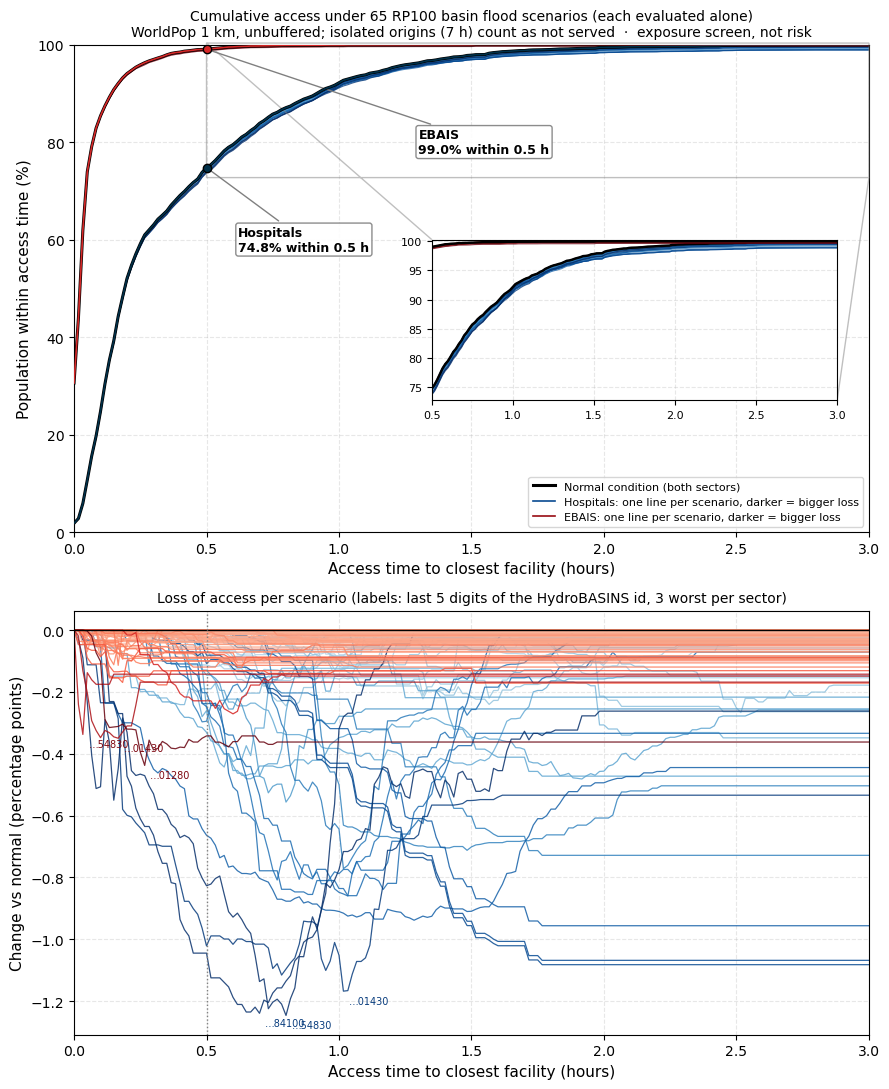

   sector within  normal_%  worst_scenario_%  median_scenario_%  scenarios_below_normal
hospitals  0.5 h      74.8              73.7               74.8                      22
hospitals    1 h      92.2              91.1               92.1                      42
    ebais  0.5 h      99.0              98.7               99.0                      42
    ebais    1 h      99.9              99.5               99.9                      46

Worst scenarios (largest loss at any time within 0-3 h, percentage points):
  hospitals 7080054830  -1.25 pp at 48 min
  hospitals 7080884100  -1.24 pp at 42 min
  hospitals 7080001430  -1.17 pp at 61 min
  ebais     7080001280  -0.44 pp at 16 min
  ebais     7080001430  -0.35 pp at 10 min
  ebais     7080054830  -0.34 pp at 2 min


In [14]:
# Cumulative access curves under every basin flood scenario, hospitals + EBAIS on one axes.
#
# ASSUMPTIONS (stated, not asked-about by the user beyond chart type / scenarios / origin set):
#  * Population basis: WorldPop 1 km ('wp'), UNBUFFERED - the user's choice.
#  * Facilities are 5b's: the official hospital register (27) and EBAIS (949), NOT the OSM
#    facilities of the 3d-OSM notebook. 5b's scenario times were routed to these sinks, so a
#    curve built on other facilities could not be combined with them. The assertion below
#    proves the recomputed baseline equals 5b's stored baseline_tt_h.
#  * Each scenario is one basin evaluated alone, never a national event (see header cell).
#  * Isolated origins carry 5b's penalty (7 h), beyond the 0-3 h axis: they count as not
#    served, exactly like "Not Accessible".
import igraph as ig
import shapely
from matplotlib.lines import Line2D

CURVE_OS = "wp"
CURVE_SECTORS = {"hospitals": "Hospitals", "ebais": "EBAIS"}
CURVE_COLORS = {"hospitals": "#003049", "ebais": "#d62828"}
thresholds = np.arange(0, 3 + 1e-9, 1 / 60)          # hours, 1-min steps (3d uses 20-min steps)

# ---- Rebuild the lean routing graph + WorldPop origins + sinks, as 5b does -------------
edges = network[["from_id", "to_id", "fft"]]
g = ig.Graph.TupleList(edges.itertuples(index=False), directed=True, edge_attrs=["fft"])
vid = {n: i for i, n in enumerate(g.vs["name"])}
first = network.geometry.apply(lambda s: shapely.Point(s.coords[0]))
last = network.geometry.apply(lambda s: shapely.Point(s.coords[-1]))
node_tbl = pd.concat([
    pd.DataFrame({"node_id": network["from_id"].values, "geometry": first.values}),
    pd.DataFrame({"node_id": network["to_id"].values, "geometry": last.values}),
]).drop_duplicates("node_id")
node_tbl["vertex_id"] = node_tbl["node_id"].map(vid)
node_tbl = node_tbl.dropna(subset=["vertex_id"]).reset_index(drop=True)
node_geoms = np.array(node_tbl["geometry"].values)
node_vids = node_tbl["vertex_id"].astype(int).to_numpy()
node_tree = shapely.STRtree(node_geoms)

def _snap(geoms):
    return node_vids[node_tree.nearest(np.asarray(geoms))]

wp_df = pd.read_csv(data_path / "cri_pd_2020_1km_UNadj_ASCII_XYZ.csv").rename(columns={"Z": "density"})
wp_df = wp_df[wp_df["density"] > 0].reset_index(drop=True)
_a = (111.320 * np.cos(np.radians(wp_df["Y"])) * (1 / 120)) * (110.574 * (1 / 120))
wp_df["population"] = wp_df["density"] * _a
wp_pts = gpd.GeoDataFrame(
    wp_df, geometry=gpd.points_from_xy(wp_df["X"], wp_df["Y"]), crs="EPSG:4326"
).to_crs(WORKING_EPSG)
wp_vertex = _snap(wp_pts.geometry.values)
wp_pop = wp_pts["population"].to_numpy(dtype=float)

hosp = gpd.read_file(data_path / "salud" / "hospitales_cr.shp").to_crs(WORKING_EPSG)
hosp = hosp[hosp["estado"] == "OK"].drop_duplicates("place_id").reset_index(drop=True)
ebs = gpd.read_file(data_path / "salud" / "ebais_cr.shp").to_crs(WORKING_EPSG).reset_index(drop=True)
sink_vertex = {"hospitals": _snap(hosp.geometry.values), "ebais": _snap(ebs.geometry.values)}

def _nearest_h(sector):
    src = np.unique(wp_vertex)
    tgt = np.unique(sink_vertex[sector])
    m = np.asarray(g.distances(source=src, target=tgt, weights="fft"))
    return pd.Series(m.min(axis=1), index=src).reindex(wp_vertex).to_numpy(dtype=float)

base_tt = {s: _nearest_h(s) for s in CURVE_SECTORS}

# ---- Check: the rebuilt baseline must be 5b's baseline --------------------------------
for s in CURVE_SECTORS:
    oa = origins_affected[(origins_affected["origin_set"] == CURVE_OS) & (origins_affected["sector"] == s)]
    pos = oa["origin_id"].astype(int).to_numpy()
    err = np.abs(base_tt[s][pos] - oa["baseline_tt_h"].to_numpy())
    assert np.nanmax(err) < 1e-6, f"{s}: rebuilt baseline differs from 5b by up to {np.nanmax(err):.2e} h"
print("Rebuilt WorldPop baseline matches 5b's stored baseline_tt_h for every affected origin.")

# ---- Curves ---------------------------------------------------------------------------
def _pct_within(tt, pop):
    return 100 * np.array([pop[tt <= t].sum() for t in thresholds]) / pop.sum()

base_curve = {s: _pct_within(base_tt[s], wp_pop) for s in CURVE_SECTORS}
scen_curves = {s: {} for s in CURVE_SECTORS}
for s in CURVE_SECTORS:
    oa = origins_affected[(origins_affected["origin_set"] == CURVE_OS) & (origins_affected["sector"] == s)]
    for sid, grp in oa.groupby("scenario_id"):
        pos = grp["origin_id"].astype(int).to_numpy()
        p = wp_pop[pos]
        b = grp["baseline_tt_h"].to_numpy()[:, None] <= thresholds[None, :]
        n = grp["scenario_tt_h"].to_numpy()[:, None] <= thresholds[None, :]
        shift = 100 * ((p[:, None] * n).sum(0) - (p[:, None] * b).sum(0)) / wp_pop.sum()
        scen_curves[s][sid] = base_curve[s] + shift
    # scenarios that affected nobody sit exactly on the baseline curve
    for sid in summary["scenario_id"].unique():
        scen_curves[s].setdefault(sid, base_curve[s].copy())

# ---- Plot -----------------------------------------------------------------------------
# Top: curves with a 0.5-3 h zoom inset. Bottom: each scenario's LOSS vs normal (percentage
# points), which is where the scenarios actually separate. Lines are coloured by the
# scenario's worst loss within its sector (darker = worse) and the worst three are labelled.
from matplotlib import cm
CURVE_CMAPS = {"hospitals": cm.Blues, "ebais": cm.Reds}
i05 = int(round(0.5 * 60))
loss = {s: {sid: c - base_curve[s] for sid, c in scen_curves[s].items()} for s in CURVE_SECTORS}
worst = {s: {sid: -l.min() for sid, l in loss[s].items()} for s in CURVE_SECTORS}   # pp
def _col(s, sid):
    top = max(max(worst[s].values()), 1e-9)
    return CURVE_CMAPS[s](0.25 + 0.75 * worst[s][sid] / top)
def _order(s):                                   # worst drawn last (on top)
    return sorted(scen_curves[s], key=lambda k: worst[s][k])
LABEL_N = 3

fig, (ax, axd) = plt.subplots(2, 1, figsize=(9, 11), facecolor="white",
                              gridspec_kw={"height_ratios": [1.15, 1]})
for s in CURVE_SECTORS:
    for sid in _order(s):
        ax.plot(thresholds, scen_curves[s][sid], color=_col(s, sid), alpha=0.8, linewidth=0.8)
    ax.plot(thresholds, base_curve[s], color="black", linewidth=2.2, zorder=10)
    ax.plot(thresholds, base_curve[s], color=CURVE_COLORS[s], linewidth=1.2, zorder=11)
    # share of population within 0.5 h under normal conditions
    ax.plot([0.5], [base_curve[s][i05]], "o", color=CURVE_COLORS[s], mec="black", zorder=12)
    ax.annotate(f"{CURVE_SECTORS[s]}\n{base_curve[s][i05]:.1f}% within 0.5 h",
                (0.5, base_curve[s][i05]),
                xytext=(1.3, 80) if s == "ebais" else (0.62, 60), textcoords="data",
                va="center", fontsize=9, fontweight="bold",
                arrowprops=dict(arrowstyle="-", color="grey"),
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="grey", alpha=0.9))

axi = ax.inset_axes([0.45, 0.27, 0.51, 0.33])
for s in CURVE_SECTORS:
    for sid in _order(s):
        axi.plot(thresholds, scen_curves[s][sid], color=_col(s, sid), alpha=0.8, linewidth=0.8)
    axi.plot(thresholds, base_curve[s], color="black", linewidth=1.8)
sel = (thresholds >= 0.5)
ylo = min(min(c[sel].min() for c in scen_curves[s].values()) for s in CURVE_SECTORS)
axi.set_xlim(0.5, 3); axi.set_ylim(ylo - 1, 100.3)
axi.grid(alpha=0.3, linestyle="--"); axi.tick_params(labelsize=8)
ax.indicate_inset_zoom(axi, edgecolor="grey")

ax.set_xlabel("Access time to closest facility (hours)", fontsize=11)
ax.set_ylabel("Population within access time (%)", fontsize=11)
ax.set_xlim(0, 3); ax.set_ylim(0, 100)
ax.grid(alpha=0.3, linestyle="--")
ax.legend(handles=(
    [Line2D([], [], color="black", linewidth=2.2, label="Normal condition (both sectors)")]
    + [Line2D([], [], color=CURVE_CMAPS[s](0.9), linewidth=1.2,
              label=f"{l}: one line per scenario, darker = bigger loss")
       for s, l in CURVE_SECTORS.items()]
), loc="lower right", fontsize=8)
ax.set_title(
    f"Cumulative access under {summary['scenario_id'].nunique()} RP{SCENARIO_RP} basin flood scenarios "
    f"(each evaluated alone)\nWorldPop 1 km, unbuffered; isolated origins ({ISOLATION_PENALTY_H:.0f} h) "
    "count as not served  ·  exposure screen, not risk", fontsize=10)

for s in CURVE_SECTORS:
    for sid in _order(s):
        axd.plot(thresholds, loss[s][sid], color=_col(s, sid), alpha=0.85, linewidth=0.9)
    for sid in _order(s)[-LABEL_N:]:
        k = int(np.argmin(loss[s][sid]))
        axd.annotate(f"…{str(sid)[-5:]}", (thresholds[k], loss[s][sid][k]), xytext=(4, -9),
                     textcoords="offset points", fontsize=7, color=CURVE_CMAPS[s](0.95))
axd.axhline(0, color="black", linewidth=1)
axd.axvline(0.5, color="grey", linestyle=":", linewidth=1)
axd.set_xlim(0, 3)
axd.set_xlabel("Access time to closest facility (hours)", fontsize=11)
axd.set_ylabel("Change vs normal (percentage points)", fontsize=11)
axd.grid(alpha=0.3, linestyle="--")
axd.set_title("Loss of access per scenario (labels: last 5 digits of the HydroBASINS id, "
              f"{LABEL_N} worst per sector)", fontsize=10)
fig.tight_layout()
fig.savefig(figure_path / "flood_scenario_access_curves.png", dpi=200, bbox_inches="tight")
plt.show()

# ---- Numbers behind the picture ---------------------------------------------------------
rows = []
for s in CURVE_SECTORS:
    for label, i in (("0.5 h", i05), ("1 h", 60)):
        at = np.array([scen_curves[s][k][i] for k in scen_curves[s]])
        rows.append({"sector": s, "within": label,
                     "normal_%": round(base_curve[s][i], 1),
                     "worst_scenario_%": round(at.min(), 1),
                     "median_scenario_%": round(float(np.median(at)), 1),
                     "scenarios_below_normal": int((at < base_curve[s][i] - 1e-9).sum())})
print(pd.DataFrame(rows).to_string(index=False))
print("\nWorst scenarios (largest loss at any time within 0-3 h, percentage points):")
for s in CURVE_SECTORS:
    for sid in _order(s)[::-1][:LABEL_N]:
        k = int(np.argmin(loss[s][sid]))
        print(f"  {s:9s} {sid}  -{worst[s][sid]:.2f} pp at {thresholds[k] * 60:.0f} min")


### Same scenarios, population on a log scale

Top: **people without access within X hours** (log y-axis), i.e. the tail of the cumulative curve in
absolute numbers. Bottom: additional people left without access vs normal, on a symlog axis (linear
below 100 people). The log axis makes the tail visible: at 3 h the unserved population differs by
orders of magnitude between scenarios, which the percentage plot above cannot show.

Assumption: "population on a log scale" is read as people *beyond* the access time, not the cumulative
population served (which compresses the scenarios into one line on a log axis). Values of zero people
cannot be drawn on a log axis and are masked.
Reuses the variables of the cell above, so run that one first. Output: `figures/flood_scenario_access_curves_log.png`.

In [ ]:
# Population WITHOUT access within X hours, on a log axis (people, not %).
# ASSUMPTION: "population as log scale" read as people beyond the access time (the tail of the
# cumulative curve), log10 y-axis. Cumulative % on a log axis would stay crowded near 100 %.
# Zero-person values cannot be drawn on a log axis and are masked (gaps = nobody unserved).
total_pop = wp_pop.sum()
def _served(curve_pct):
    return curve_pct / 100 * total_pop
def _unserved(curve_pct):
    return (100 - curve_pct) / 100 * total_pop

fig, (axl, axr) = plt.subplots(2, 1, figsize=(9, 11), facecolor="white",
                               gridspec_kw={"height_ratios": [1.15, 1]})
for s in CURVE_SECTORS:
    for sid in _order(s):
        y = _unserved(scen_curves[s][sid])
        axl.plot(thresholds, np.where(y > 1, y, np.nan), color=_col(s, sid), alpha=0.8, linewidth=0.8)
    yb = _unserved(base_curve[s])
    axl.plot(thresholds, np.where(yb > 1, yb, np.nan), color="black", linewidth=2.2, zorder=10)
    axl.plot(thresholds, np.where(yb > 1, yb, np.nan), color=CURVE_COLORS[s], linewidth=1.2, zorder=11)
    axl.plot([0.5], [yb[i05]], "o", color=CURVE_COLORS[s], mec="black", zorder=12)
    axl.annotate(f"{CURVE_SECTORS[s]}\n{yb[i05]:,.0f} people ({100 - base_curve[s][i05]:.1f}%)\nbeyond 0.5 h",
                 (0.5, yb[i05]), xytext=(0.75, yb[i05] * 3) if s == "hospitals" else (0.08, 2500),
                 textcoords="data", va="center", fontsize=8.5, fontweight="bold",
                 arrowprops=dict(arrowstyle="-", color="grey"),
                 bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="grey", alpha=0.9))
axl.set_yscale("log")
axl.set_xlim(0, 3)
axl.set_xlabel("Access time to closest facility (hours)", fontsize=11)
axl.set_ylabel("Population beyond access time (people, log scale)", fontsize=11)
axp = axl.secondary_yaxis("right", functions=(lambda y: y / total_pop * 100,
                                              lambda p: p * total_pop / 100))
axp.set_ylabel("Population beyond access time (% of total, log scale)", fontsize=11)
axp.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}%"))
axl.grid(alpha=0.3, linestyle="--", which="both")
axl.legend(handles=(
    [Line2D([], [], color="black", linewidth=2.2, label="Normal condition (both sectors)")]
    + [Line2D([], [], color=CURVE_CMAPS[s](0.9), linewidth=1.2,
              label=f"{l}: one line per scenario, darker = bigger loss")
       for s, l in CURVE_SECTORS.items()]
), loc="upper right", fontsize=8)
axl.set_title(
    f"People without access within X hours, {summary['scenario_id'].nunique()} RP{SCENARIO_RP} basin scenarios "
    f"(each evaluated alone)\nWorldPop 1 km ({total_pop:,.0f} people), unbuffered; isolated origins "
    "count as unserved\nexposure screen, not risk", fontsize=10)

# Bottom: extra people unserved vs normal, symlog so that small and large scenarios both show.
for s in CURVE_SECTORS:
    for sid in _order(s):
        axr.plot(thresholds, _unserved(scen_curves[s][sid]) - _unserved(base_curve[s]),
                 color=_col(s, sid), alpha=0.85, linewidth=0.9)
axr.set_yscale("symlog", linthresh=100)
axr.axvline(0.5, color="grey", linestyle=":", linewidth=1)
axr.set_xlim(0, 3)
axr.set_xlabel("Access time to closest facility (hours)", fontsize=11)
axr.set_ylabel("Additional people beyond access time\n(symlog, linear below 100)", fontsize=11)
axr.grid(alpha=0.3, linestyle="--", which="both")
axr.set_title("Additional people without access, per scenario, relative to normal", fontsize=10)
fig.tight_layout()
fig.savefig(figure_path / "flood_scenario_access_curves_log.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"{'sector':9s} {'beyond 0.5 h normal':>20s} {'beyond 1 h normal':>18s} {'beyond 1 h worst':>17s}")
for s in CURVE_SECTORS:
    w1 = max(_unserved(scen_curves[s][k])[60] for k in scen_curves[s])
    print(f"{s:9s} {_unserved(base_curve[s])[i05]:20,.0f} {_unserved(base_curve[s])[60]:18,.0f} {w1:17,.0f}")
